# Otimização do Random Forest – Passo 4: tamanho do candle × janela de treino (abordagem B)

**Pergunta:** com o classificador de 3 classes (sobe > 5 pts / neutro / desce > 5 pts), qual tamanho de candle e qual
janela de treino dão o melhor retorno por capital?

**Por que refazer a grade:** na rodada anterior, a grade foi feita com o regressor e decidida pelo Theil U (erro de
previsão). Agora o alvo é outro (o movimento paga o custo?) e o objetivo é o retorno. Candles maiores têm movimentos
maiores em relação ao custo fixo de 5 pts, então o cenário vencedor pode mudar.

**Grade:** candle de 1, **5** (novo), 15 e 60 min × janela de 1, 3, 6 e 12 meses = 16 cenários. O 5 min entra porque a
regra "segurar" funcionou melhor com posições de 10–20 min, entre o 1 min e o 15 min.

**Fixo nesta etapa** (para mudar uma coisa de cada vez): 16 variáveis `COMPLETO`, floresta `rf_d4_f2` (100 árvores,
profundidade 4, folha mínima 2% do treino), corte das classes em 5 pts, custo de 5 pts, regras `por_candle` e
`segurar` com limiar nos quantis 0–98% do |P(sobe) − P(desce)|.

**Só validação (2024).** O teste não é usado.

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))   # notebook em frentes/ml/

sys.path.append(PASTA)
sys.path.append(f"{PASTA}/frentes/ml")
import tt1_comum as t
import otim_rf as o

SAIDA = f"{PASTA}/resultados/ml/otimizacao"
os.makedirs(f"{SAIDA}/previsoes", exist_ok=True)
CANDLES = ["1min", "5min", "15min", "60min"]
JANELAS = [1, 3, 6, 12]
FEATS = t.features()["COMPLETO"]

## Registro do critério (antes de rodar)

1. **Candidata:** configuração (cenário × regra × limiar) com esperança > 0 com custo de 5 pts, **t ≥ 2** e lucro em
   **≥ 3 dos 4 trimestres** de 2024.
2. **Se houver candidatas:** vence o cenário da candidata com maior retorno sobre capital.
3. **Se não houver:** vence o cenário com **maior t do ganho bruto** (sem custo, operando todo candle na direção do
   sinal), o mesmo desempate do passo 2. Ele mede onde o sinal é mais confiável. Ressalva: o t cresce com o número de
   candles, o que favorece candles menores; por isso também reportamos o Spearman, que não depende do tamanho da amostra.

In [2]:
REGISTRO = dict(passo="4 - candle × janela", abordagem="B (classificador 3 classes, sinal = P(sobe) − P(desce))",
                candles=CANDLES, janelas_meses=JANELAS, floresta=o.RF_PADRAO, corte_classe_pts=o.CORTE_CLASSE,
                custo_pts=o.CUSTO, quantis=o.QUANTIS, regras=["por_candle", "segurar"],
                criterio_candidata=f"esperança > 0, t ≥ {o.T_MIN}, lucro em ≥ {o.TRIM_MIN} de 4 trimestres",
                criterio_com_candidatas="maior retorno sobre capital",
                criterio_sem_candidatas="maior t do ganho bruto (custo 0, todo candle)",
                periodo="validação 2024")
json.dump(REGISTRO, open(f"{SAIDA}/registro_passo4.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

## Rodada da grade

Para cada cenário: walk-forward trimestral na validação, previsões salvas, qualidade do sinal e as 12 regras
(2 regras × 6 limiares) com a referência aleatória.

In [3]:
win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")

grade, regras, treinos = [], [], []
for candle in CANDLES:
    df, s = t.montar_base(win, wdo, candle)
    df = o.rotular(df)
    val = df[(df.index >= t.VALIDACAO[0]) & (df.index < t.VALIDACAO[1])]
    dist = val.classe.value_counts(normalize=True)
    for jm in JANELAS:
        t0 = time.time()
        prev, info = o.walk_forward_b(df, FEATS, *t.VALIDACAO, janela_meses=jm)
        seg = time.time() - t0
        prev.to_csv(f"{SAIDA}/previsoes/WIN_{candle}_{jm}m_rfB_val.csv")
        g = o.grade_regras(prev).assign(candle=candle, janela_meses=jm)
        regras.append(g)
        treinos.append(info.assign(candle=candle, janela_meses=jm))
        m = g[g.serie == "modelo"]
        best = m.sort_values("esperanca_pts", ascending=False).iloc[0]
        grade.append(dict(candle=candle, janela_meses=jm, candles_por_pregao=s, n_val=len(prev),
                          n_treino_medio=int(info.n_treino.mean()), folha_min_media=int(info.folha_min.mean()),
                          pct_sobe=dist.get(1, 0), pct_neutro=dist.get(0, 0), pct_desce=dist.get(-1, 0),
                          tempo_s=round(seg, 1), **o.qualidade(prev),
                          melhor_regra=best.regra, melhor_limiar_q=best.limiar_q, melhor_esperanca=best.esperanca_pts,
                          melhor_t=best.t_stat, melhor_lucro_R=best.lucro_R, melhor_retorno_capital=best.retorno_capital,
                          melhor_trim_pos=best.trimestres_positivos, n_candidatas=int(g.candidata.sum())))
        print(f"{candle:>5} {jm:>2}m | treino ~{int(info.n_treino.mean()):,} | Spearman {grade[-1]['spearman']:+.4f} | "
              f"bruto {grade[-1]['bruto_esperanca_pts']:+.2f} pts (t {grade[-1]['bruto_t_stat']:+.2f}) | "
              f"melhor regra {best.regra} q{best.limiar_q:.0%}: {best.esperanca_pts:+.2f} (t {best.t_stat:+.2f}) | {seg:.0f}s")

grade = pd.DataFrame(grade)
regras = pd.concat(regras, ignore_index=True)
treinos = pd.concat(treinos, ignore_index=True)
grade.to_csv(f"{SAIDA}/grade_B_val.csv", index=False)
regras.to_csv(f"{SAIDA}/grade_B_regras_val.csv", index=False)
treinos.to_csv(f"{SAIDA}/grade_B_treinos.csv", index=False)

 1min  1m | treino ~11,256 | Spearman +0.0154 | bruto +0.26 pts (t +2.31) | melhor regra segurar q90%: +1.14 (t +0.24) | 2s


 1min  3m | treino ~33,533 | Spearman +0.0165 | bruto +0.33 pts (t +2.95) | melhor regra segurar q75%: -3.06 (t -2.47) | 5s


 1min  6m | treino ~57,777 | Spearman +0.0177 | bruto +0.29 pts (t +2.54) | melhor regra segurar q75%: -3.16 (t -2.65) | 8s


 1min 12m | treino ~99,892 | Spearman +0.0193 | bruto +0.40 pts (t +3.57) | melhor regra segurar q75%: -1.87 (t -1.30) | 14s


 5min  1m | treino ~2,236 | Spearman +0.0102 | bruto +0.63 pts (t +1.14) | melhor regra segurar q95%: +18.69 (t +0.32) | 1s


 5min  3m | treino ~6,661 | Spearman +0.0142 | bruto +0.15 pts (t +0.28) | melhor regra segurar q75%: +3.54 (t +0.19) | 1s


... (6 outputs left out)

60min  1m | treino ~178 | Spearman +0.0088 | bruto +1.74 pts (t +0.28) | melhor regra por_candle q95%: +17.39 (t +0.56) | 0s


60min  3m | treino ~532 | Spearman -0.0315 | bruto -8.83 pts (t -1.42) | melhor regra segurar q98%: +157.56 (t +1.72) | 1s


60min  6m | treino ~918 | Spearman -0.0140 | bruto -7.88 pts (t -1.27) | melhor regra por_candle q95%: -5.84 (t -0.24) | 1s


60min 12m | treino ~1,574 | Spearman +0.0282 | bruto +0.88 pts (t +0.14) | melhor regra por_candle q98%: +10.76 (t +0.40) | 1s


## Qualidade do sinal por cenário

- **Spearman:** correlação entre a ordem dos sinais e a ordem dos movimentos do candle seguinte (não depende do nº de candles).
- **Ganho bruto:** pontos médios por operação operando todo candle, **sem custo**. Mede o tamanho da vantagem em pontos.
- **t do ganho bruto:** ganho ÷ erro-padrão. Mede se a vantagem é distinguível de zero.

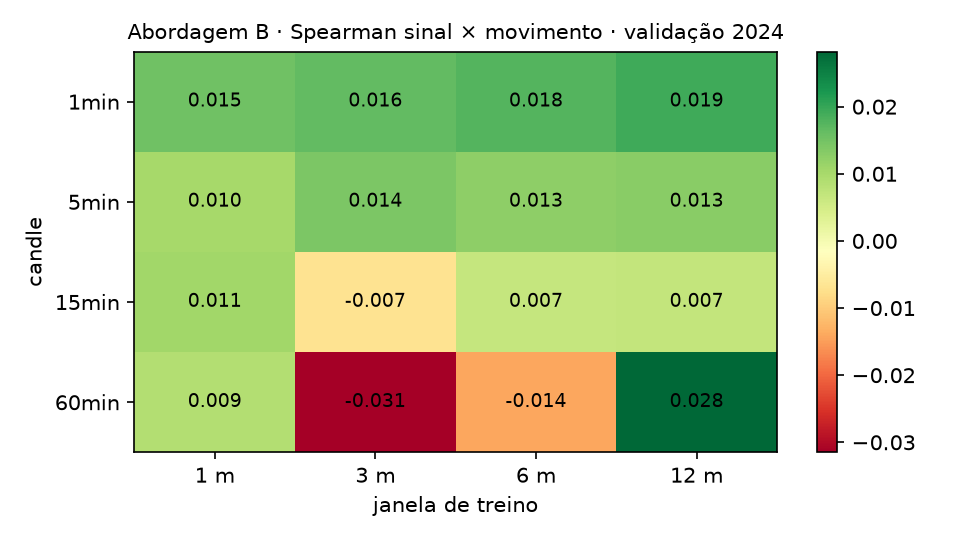

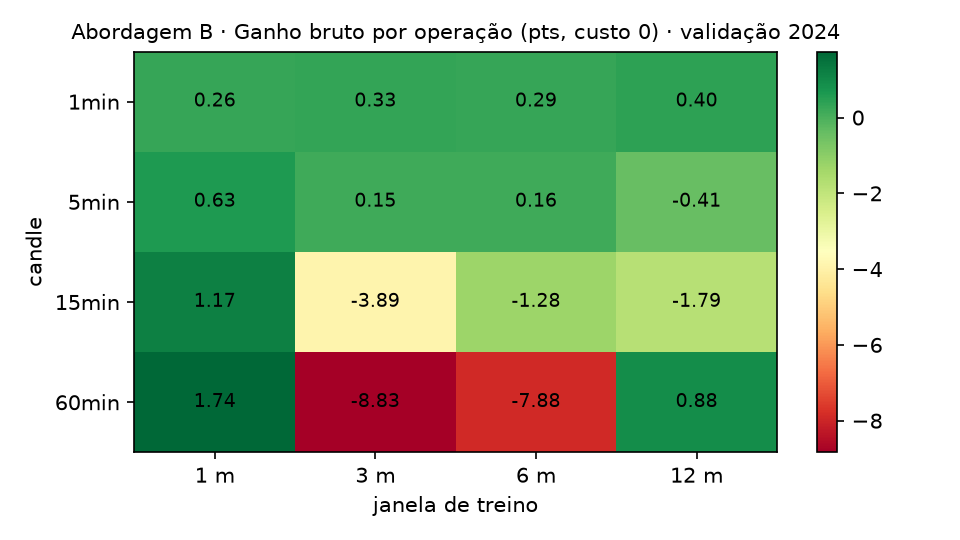

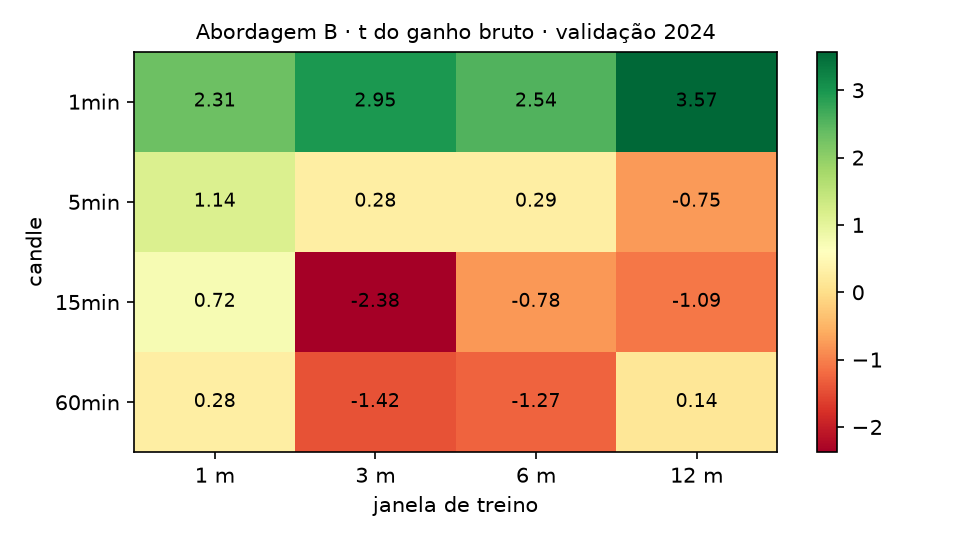

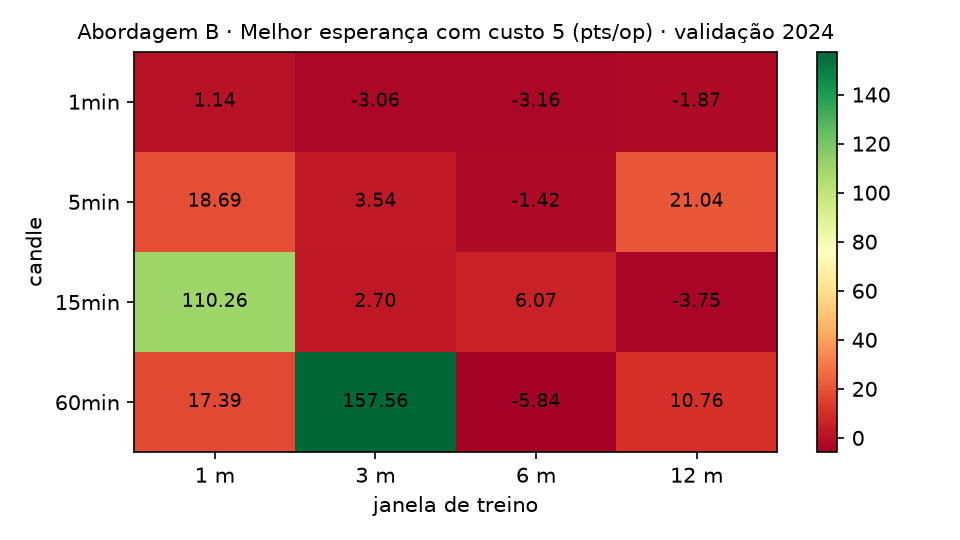

,candle,janela_meses,n_treino_medio,folha_min_media,pct_neutro,spearman,acc_dir,bruto_esperanca_pts,bruto_t_stat
0,1min,1,11256,224,0.2002,0.0154,0.5101,0.2590,2.3105
1,1min,3,33533,670,0.2002,0.0165,0.5100,0.3309,2.9524
2,1min,6,57777,1155,0.2002,0.0177,0.5098,0.2853,2.5449
3,1min,12,99892,1997,0.2002,0.0193,0.5117,0.4007,3.5747
4,5min,1,2236,44,0.0882,0.0102,0.5078,0.6267,1.1426
5,5min,3,6661,132,0.0882,0.0142,0.5087,0.1544,0.2814
6,5min,6,11478,229,0.0882,0.0125,0.5073,0.1590,0.2899
7,5min,12,19842,396,0.0882,0.0129,0.5061,-0.4114,-0.7500
8,15min,1,738,14,0.0539,0.0107,0.5082,1.1734,0.7171
9,15min,3,2200,43,0.0539,-0.0070,0.4969,-3.8860,-2.3755


In [4]:
for col, tit, fmt in [("spearman", "Spearman sinal × movimento", ".3f"),
                      ("bruto_esperanca_pts", "Ganho bruto por operação (pts, custo 0)", ".2f"),
                      ("bruto_t_stat", "t do ganho bruto", ".2f"),
                      ("melhor_esperanca", "Melhor esperança com custo 5 (pts/op)", ".2f")]:
    o.heatmap(grade, col, f"Abordagem B · {tit} · validação 2024", f"{SAIDA}/heatmap_B_{col}.png", CANDLES, fmt)
from IPython.display import Image, display
for col in ["spearman", "bruto_esperanca_pts", "bruto_t_stat", "melhor_esperanca"]:
    display(Image(f"{SAIDA}/heatmap_B_{col}.png"))
grade[["candle", "janela_meses", "n_treino_medio", "folha_min_media", "pct_neutro", "spearman", "acc_dir",
       "bruto_esperanca_pts", "bruto_t_stat"]].round(4)

## Melhor regra de cada cenário (custo de 5 pts)

In [5]:
grade[["candle", "janela_meses", "melhor_regra", "melhor_limiar_q", "melhor_esperanca", "melhor_t", "melhor_lucro_R",
       "melhor_retorno_capital", "melhor_trim_pos", "n_candidatas"]].round(3)

,candle,janela_meses,melhor_regra,melhor_limiar_q,melhor_esperanca,melhor_t,melhor_lucro_R,melhor_retorno_capital,melhor_trim_pos,n_candidatas
0,1min,1,segurar,0.90,1.143,0.238,654.0,0.275,3,0
1,1min,3,segurar,0.75,-3.061,-2.471,-6975.0,-0.842,1,0
2,1min,6,segurar,0.75,-3.159,-2.655,-7663.0,-0.860,1,0
3,1min,12,segurar,0.75,-1.873,-1.295,-3610.0,-0.720,2,0
4,5min,1,segurar,0.95,18.688,0.325,826.0,0.223,2,0
5,5min,3,segurar,0.75,3.541,0.187,592.0,0.152,1,0
6,5min,6,segurar,0.75,-1.425,-0.048,-151.0,-0.039,2,0
7,5min,12,segurar,0.95,21.037,0.521,1014.0,0.656,2,0
8,15min,1,segurar,0.98,110.263,1.510,2095.0,2.133,2,0
9,15min,3,segurar,0.98,2.704,0.047,53.0,0.057,1,0


## Todas as configurações com esperança positiva (se houver)

Com 16 cenários × 12 regras = 192 configurações, algumas vão parecer boas por sorte. Por isso a exigência de t ≥ 2 e de
consistência entre trimestres.

In [6]:
pos = regras[(regras.serie == "modelo") & (regras.esperanca_pts > 0)].sort_values("esperanca_pts", ascending=False)
print(f"Configurações com esperança > 0: {len(pos)} de {int((regras.serie == 'modelo').sum())} | "
      f"candidatas (t ≥ 2 e ≥ 3 trimestres): {int(regras.candidata.sum())}")
pos[["candle", "janela_meses", "regra", "limiar_q", "n_ops", "ops_por_dia", "candles_medios", "esperanca_pts", "t_stat",
     "lucro_R", "drawdown_R", "retorno_capital", "trimestres_positivos", "candidata"]].round(3).head(20)

Configurações com esperança > 0: 22 de 192 | candidatas (t ≥ 2 e ≥ 3 trimestres): 0


,candle,janela_meses,regra,limiar_q,n_ops,ops_por_dia,candles_medios,esperanca_pts,t_stat,lucro_R,drawdown_R,retorno_capital,trimestres_positivos,candidata
334,60min,3,segurar,0.98,41,0.163,4.415,157.561,1.718,1292.0,270.0,3.076,3,False
214,15min,1,segurar,0.98,95,0.378,23.979,110.263,1.510,2095.0,832.0,2.133,2,False
210,15min,1,segurar,0.95,128,0.510,28.227,88.398,1.220,2263.0,1798.0,1.162,3,False
206,15min,1,segurar,0.90,184,0.733,27.261,75.788,1.323,2789.0,1790.0,1.438,3,False
186,5min,12,segurar,0.95,241,0.960,47.506,21.037,0.521,1014.0,1395.0,0.656,2,False
114,5min,1,segurar,0.95,221,0.880,82.122,18.688,0.325,826.0,3556.0,0.223,2,False
304,60min,1,por_candle,0.95,113,0.450,1.000,17.389,0.559,393.0,552.0,0.560,2,False
178,5min,12,segurar,0.75,704,2.805,35.041,13.288,0.644,1871.0,2495.0,0.707,2,False
380,60min,12,por_candle,0.98,46,0.183,1.000,10.761,0.396,99.0,240.0,0.254,1,False
294,60min,1,segurar,0.50,392,1.562,5.171,10.242,0.313,803.0,2621.0,0.290,2,False


## Decisão do passo 4

In [7]:
cand = regras[regras.candidata].sort_values("retorno_capital", ascending=False)
if len(cand):
    v = cand.iloc[0]
    CANDLE, JANELA = v.candle, int(v.janela_meses)
    CRITERIO = "maior retorno sobre capital entre as candidatas"
else:
    v = grade.sort_values("bruto_t_stat", ascending=False).iloc[0]
    CANDLE, JANELA = v.candle, int(v.janela_meses)
    CRITERIO = "nenhuma candidata: maior t do ganho bruto (sinal mais confiável)"
linha = grade[(grade.candle == CANDLE) & (grade.janela_meses == JANELA)].iloc[0]
print("Critério:", CRITERIO)
print(f"Cenário escolhido: {CANDLE} × {JANELA} meses | Spearman {linha.spearman:.4f} | ganho bruto "
      f"{linha.bruto_esperanca_pts:+.2f} pts (t {linha.bruto_t_stat:.2f}) | melhor regra {linha.melhor_regra} "
      f"q{linha.melhor_limiar_q:.0%}: {linha.melhor_esperanca:+.2f} pts/op (t {linha.melhor_t:.2f})")
decisao = dict(passo="4 - candle × janela", criterio=CRITERIO, candle=CANDLE, janela_meses=JANELA,
               n_candidatas=int(regras.candidata.sum()), spearman=float(linha.spearman),
               bruto_pts=float(linha.bruto_esperanca_pts), bruto_t=float(linha.bruto_t_stat),
               melhor_regra=linha.melhor_regra, melhor_limiar_q=float(linha.melhor_limiar_q),
               melhor_esperanca=float(linha.melhor_esperanca), melhor_t=float(linha.melhor_t))
json.dump(decisao, open(f"{SAIDA}/decisao_passo4.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

Critério: nenhuma candidata: maior t do ganho bruto (sinal mais confiável)
Cenário escolhido: 1min × 12 meses | Spearman 0.0193 | ganho bruto +0.40 pts (t 3.57) | melhor regra segurar q75%: -1.87 pts/op (t -1.30)


## O efeito do tamanho do candle sobre o custo

O custo é fixo em pontos. Quanto maior o candle, maior o movimento típico e menor o peso relativo do custo, mas
também menos candles para treinar e operar.

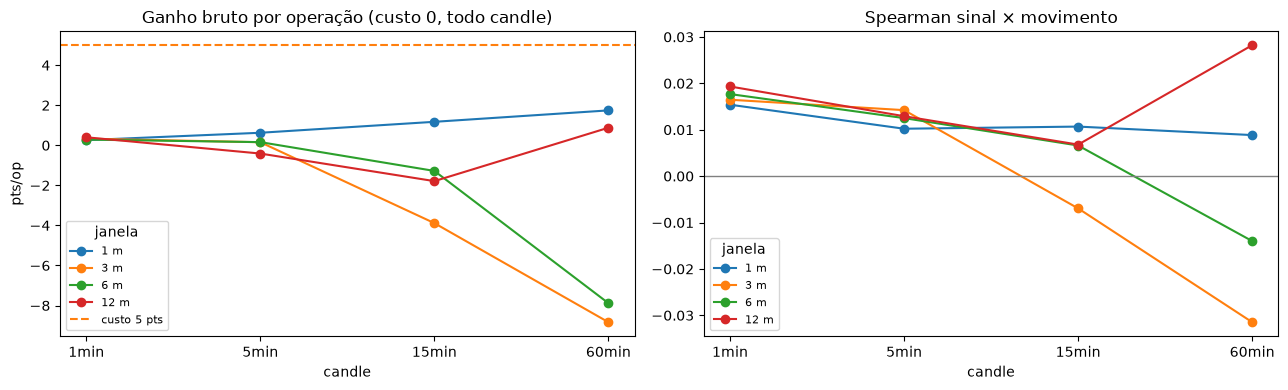

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for jm in JANELAS:
    g = grade[grade.janela_meses == jm].set_index("candle").reindex(CANDLES)
    axes[0].plot(CANDLES, g.bruto_esperanca_pts, "o-", label=f"{jm} m")
    axes[1].plot(CANDLES, g.spearman, "o-", label=f"{jm} m")
axes[0].axhline(o.CUSTO, color="tab:orange", ls="--", label="custo 5 pts")
axes[0].set_title("Ganho bruto por operação (custo 0, todo candle)"); axes[0].set_ylabel("pts/op")
axes[1].axhline(0, color="gray", lw=1); axes[1].set_title("Spearman sinal × movimento")
for ax in axes:
    ax.set_xlabel("candle"); ax.legend(title="janela", fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/grade_B_candle.png", dpi=150); plt.show()